# The Master Boot Cell

In [ ]:
import os
from datetime import datetime
import pytz

print("⚙️ INITIATING SYSTEM BOOT SEQUENCE...")

# ==========================================
# 1. MOUNT GOOGLE DRIVE AUTOMATICALLY
# ==========================================
from google.colab import drive
if not os.path.exists('/content/drive'):
    print("📂 Mounting Google Drive...")
    drive.mount('/content/drive')
else:
    print("✅ Google Drive already mounted.")

# Ensure we are working in the Version 6 folder
os.chdir('/content/drive/MyDrive/Thesis/Version 6/')

# ==========================================
# 2. LOAD PROGRESS TRACKER
# ==========================================
dhaka_tz = pytz.timezone('Asia/Dhaka')
tracker_path = '/content/drive/MyDrive/Thesis/Version 6/Thesis_Progress_Tracker.txt'

def update_progress(task_description):
    now = datetime.now(dhaka_tz).strftime("%Y-%m-%d %I:%M:%S %p")
    with open(tracker_path, 'a') as f:
        f.write(f"[{now}] {task_description}\n")
    print(f"✅ Logged to Tracker: {task_description}")

print("✅ Progress Tracker Online.")

# ==========================================
# 3. VERIFY T4 GPU IS ACTIVE
# ==========================================
import torch
if torch.cuda.is_available():
    print(f"✅ GPU IS ACTIVE: {torch.cuda.get_device_name(0)}")
else:
    print("❌ WARNING: CPU DETECTED! Go to Runtime > Change runtime type and select T4 GPU.")

# ==========================================
# 4. INSTALL REQUIRED LIBRARIES
# ==========================================
try:
    import ultralytics
except ImportError:
    print("📦 Installing Ultralytics YOLO framework...")
    !pip install ultralytics -q


⚙️ INITIATING SYSTEM BOOT SEQUENCE...
📂 Mounting Google Drive...
Mounted at /content/drive
✅ Progress Tracker Online.
❌ WARNING: CPU DETECTED! Go to Runtime > Change runtime type and select T4 GPU.
📦 Installing Ultralytics YOLO framework...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 20.5 MB/s eta 0:00:00


# update_progress()

In [ ]:
import os
from datetime import datetime
import pytz

# ==========================================
# 1. SETUP THE TRACKER
# ==========================================
tracker_path = '/content/drive/MyDrive/Thesis/Version 6/Thesis_Progress_Tracker.txt'

# Setting timezone to Dhaka
dhaka_tz = pytz.timezone('Asia/Dhaka')

def update_progress(task_description):
    now = datetime.now(dhaka_tz).strftime("%Y-%m-%d %I:%M:%S %p")
    entry = f"[{now}] {task_description}\n"

    # Create the file with a header if it doesn't exist
    if not os.path.exists(tracker_path):
        with open(tracker_path, 'w') as f:
            f.write("="*60 + "\n")
            f.write("🎓 Q1 THESIS PROGRESS TRACKER\n")
            f.write("="*60 + "\n\n")

    # Append the new log
    with open(tracker_path, 'a') as f:
        f.write(entry)

    print(f"✅ Logged to Tracker: {task_description}")

# ==========================================
# 2. LOG TODAY'S ARCHITECTURAL DECISIONS
# ==========================================
update_progress("Finalized Q1 Methodology: YOLO26 + CBAM + DCFM with MOT Risk Assessment.")
update_progress("Phase 1.1 Commenced: Selected VisDrone as the public benchmark to prove small-object detection superiority.")

✅ Logged to Tracker: Finalized Q1 Methodology: YOLO26 + CBAM + DCFM with MOT Risk Assessment.
✅ Logged to Tracker: Phase 1.1 Commenced: Selected VisDrone as the public benchmark to prove small-object detection superiority.


# Phase 1.1: Securing VisDrone

In [ ]:
import os
from ultralytics.utils.downloads import download

print("🚀 Commencing Phase 1.1: Downloading VisDrone Public Benchmark...")

# Ultralytics natively supports downloading VisDrone via its YAML configuration.
# We will create the target directory in Colab's high-speed local storage.
dataset_dir = '/content/datasets'
os.makedirs(dataset_dir, exist_ok=True)

# Change working directory so it downloads locally, not to Drive
os.chdir(dataset_dir)

# The official Ultralytics script to download and unzip VisDrone (~1.5 GB)
# This includes Train, Val, and Test splits perfectly formatted for YOLO.
try:
    from ultralytics.data.utils import check_det_dataset
    print("📥 Downloading and unzipping VisDrone data (This may take a few minutes)...")
    check_det_dataset('VisDrone.yaml')
    print("\n✅ VisDrone successfully downloaded and formatted!")

    # Log the successful download
    update_progress("Phase 1.1 Complete: Successfully downloaded and formatted VisDrone dataset to local Colab storage.")
except Exception as e:
    print(f"❌ Error downloading VisDrone: {e}")

# Return working directory to your thesis folder for safety
os.chdir('/content/drive/MyDrive/Thesis/Version 6/')

🚀 Commencing Phase 1.1: Downloading VisDrone Public Benchmark...
📥 Downloading and unzipping VisDrone data (This may take a few minutes)...

✅ VisDrone successfully downloaded and formatted!
✅ Logged to Tracker: Phase 1.1 Complete: Successfully downloaded and formatted VisDrone dataset to local Colab storage.


# Phase 2.2: The VisDrone Baseline

## The Baseline Launch Sequence

### Step 1

In [ ]:
from ultralytics import YOLO

print("🚀 Waking up the official YOLO26m Baseline Model...")

# 1. Load the raw, unmodified YOLO26 Medium model
model = YOLO('yolo26m.pt')

# 2. Launch Baseline Training on VisDrone
print("🔥 Initiating Phase 2.2: Training Baseline on VisDrone dataset...")
results = model.train(
    data='VisDrone.yaml',         # Ultralytics natively knows where we saved this locally
    epochs=50,                    # 50 epochs is a solid, defensible baseline for a Q1 paper
    imgsz=640,                    # Standard resolution for fair comparison
    batch=16,                     # Perfect batch size for the T4 GPU's VRAM
    project='/content/drive/MyDrive/Thesis/Version 6/Training_Runs',
    name='VisDrone_YOLO26m_Baseline',
    patience=10,                  # Early stopping if accuracy flatlines for 10 epochs
    save=True,                    # Save the best model weights to your Drive
    device=0                      # This forces it to use the T4 GPU!
)

print("✅ Baseline Training Complete!")

🚀 Waking up the official YOLO26m Baseline Model...
🔥 Initiating Phase 2.2: Training Baseline on VisDrone dataset...
Ultralytics 8.4.38 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=VisDrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=VisDr

In [ ]:
from datetime import datetime
import pytz

dhaka_tz = pytz.timezone('Asia/Dhaka')
tracker_path = '/content/drive/MyDrive/Thesis/Version 6/Thesis_Progress_Tracker.txt'

def update_progress(task_description):
    now = datetime.now(dhaka_tz).strftime("%Y-%m-%d %I:%M:%S %p")
    with open(tracker_path, 'a') as f:
        f.write(f"[{now}] {task_description}\n")
    print(f"✅ Logged to Tracker: {task_description}")

# Log the Baseline Metrics
update_progress("Phase 2.2 Complete: VisDrone YOLO26m Baseline finished (Early Stop at Ep 38/50).")
update_progress("VisDrone Baseline Metrics Logged - Overall mAP50: 45.0%. Small objects (bicycles) identified as primary weakness (20.4%), justifying DCFM integration.")

✅ Logged to Tracker: Phase 2.2 Complete: VisDrone YOLO26m Baseline finished (Early Stop at Ep 38/50).
Unzipping /content/drive/MyDrive/Thesis/Version 6/datasets/VisDrone/VisDrone2019-DET-train.zip to /content/drive/MyDrive/Thesis/Version 6/datasets/VisDrone/VisDrone2019-DET-train...: 25% ━━━───────── 3247/12945 28.4files/s 1:32<5:42✅ Logged to Tracker: VisDrone Baseline Metrics Logged - Overall mAP50: 45.0%. Small objects (bicycles) identified as primary weakness (20.4%), justifying DCFM integration.


# Phase 1.3 (Dhaka Video-Wise Split)

## The "Pre-Flight" QA Scanner

In [ ]:
import os
from tqdm import tqdm

# ==========================================
# 1. PATH TO YOUR MASTER LABELS
# ==========================================
labels_dir = '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset/labels/train/'

# ==========================================
# 2. QA SCANNER ENGINE
# ==========================================
print("🔍 Initiating QA Pre-Flight Scan on all annotations...")

valid_classes = set(range(9))  # IDs 0 through 8
total_files = 0
empty_files = 0
corrupt_files = []
invalid_class_files = []
out_of_bounds_files = []

# Class distribution counter
class_counts = {i: 0 for i in range(9)}

txt_files = [f for f in os.listdir(labels_dir) if f.endswith('.txt')]

for txt in tqdm(txt_files, desc="Scanning Annotations"):
    total_files += 1
    file_path = os.path.join(labels_dir, txt)

    with open(file_path, 'r') as f:
        lines = f.readlines()

    if not lines:
        empty_files += 1
        continue

    for line in lines:
        parts = line.strip().split()

        # Check 1: Is it formatted correctly? (Class + 4 coordinates)
        if len(parts) != 5:
            corrupt_files.append(txt)
            break

        try:
            class_id = int(parts[0])
            x, y, w, h = map(float, parts[1:])

            # Check 2: Is the Class ID valid?
            if class_id not in valid_classes:
                invalid_class_files.append((txt, class_id))

            # Check 3: Are coordinates normalized between 0 and 1?
            if not (0.0 <= x <= 1.0 and 0.0 <= y <= 1.0 and 0.0 <= w <= 1.0 and 0.0 <= h <= 1.0):
                out_of_bounds_files.append(txt)

            # Count the class for our dataset statistics
            if class_id in valid_classes:
                class_counts[class_id] += 1

        except ValueError:
            corrupt_files.append(txt)
            break

# ==========================================
# 3. QA REPORT
# ==========================================
print("\n" + "="*50)
print("📊 DATASET QUALITY ASSURANCE REPORT 📊")
print("="*50)
print(f"Total Files Scanned: {total_files:,}")
print(f"Empty Files (Background images): {empty_files:,}")
print(f"❌ Corrupt Formatting: {len(corrupt_files):,}")
print(f"❌ Invalid Class IDs (Not 0-8): {len(invalid_class_files):,}")
print(f"❌ Out of Bounds Coordinates: {len(out_of_bounds_files):,}")
print("-" * 50)
print("📈 CLASS DISTRIBUTION:")
class_names = {0: 'Bike', 1: 'Bus', 2: 'Car', 3: 'CNG', 4: 'Cycle', 5: 'Rider', 6: 'People', 7: 'Rickshaw', 8: 'Truck'}
for cid, count in class_counts.items():
    print(f"Class {cid} ({class_names[cid]}): {count:,} objects")
print("="*50)

🔍 Initiating QA Pre-Flight Scan on all annotations...


Scanning Annotations:  47%|████▋     | 12872/27578 [1:48:39<1:48:58,  2.25it/s]

In [ ]:
import os
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
from collections import Counter

# ==========================================
# 1. PATH TO YOUR MASTER LABELS
# ==========================================
labels_dir = '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset/labels/train/'

# ==========================================
# 2. HYPER-SPEED QA SCANNER ENGINE
# ==========================================
print("🔍 Fetching file list from Google Drive (this may take 30-60 seconds)...")
txt_files = [f for f in os.listdir(labels_dir) if f.endswith('.txt')]
print(f"✅ Found {len(txt_files):,} files. Initiating Hyper-Speed Multi-Threaded Scan...")

valid_classes = set(range(9))

def check_file(txt):
    file_path = os.path.join(labels_dir, txt)
    try:
        with open(file_path, 'r') as f:
            lines = f.readlines()
    except Exception:
        return 'read_error', txt

    if not lines:
        return 'empty', txt

    found_classes = []
    for line in lines:
        parts = line.strip().split()

        if len(parts) != 5:
            return 'corrupt', txt

        try:
            class_id = int(parts[0])
            x, y, w, h = map(float, parts[1:])

            if class_id not in valid_classes:
                return 'invalid_class', txt

            if not (0.0 <= x <= 1.0 and 0.0 <= y <= 1.0 and 0.0 <= w <= 1.0 and 0.0 <= h <= 1.0):
                return 'out_of_bounds', txt

            found_classes.append(class_id)
        except ValueError:
            return 'corrupt', txt

    return 'ok', found_classes

# ==========================================
# 3. EXECUTE WITH 32 THREADS
# ==========================================
empty_files = 0
corrupt_files = []
invalid_class_files = []
out_of_bounds_files = []
class_counts = Counter()

# Using 32 workers to overwhelm the Google Drive latency bottleneck
with ThreadPoolExecutor(max_workers=32) as executor:
    results = list(tqdm(executor.map(check_file, txt_files), total=len(txt_files), desc="Scanning Annotations"))

# ==========================================
# 4. PROCESS RESULTS
# ==========================================
for status, data in results:
    if status == 'empty':
        empty_files += 1
    elif status == 'corrupt':
        corrupt_files.append(data)
    elif status == 'invalid_class':
        invalid_class_files.append(data)
    elif status == 'out_of_bounds':
        out_of_bounds_files.append(data)
    elif status == 'ok':
        class_counts.update(data)

print("\n" + "="*50)
print("📊 FAST DATASET QUALITY ASSURANCE REPORT 📊")
print("="*50)
print(f"Total Files Scanned: {len(txt_files):,}")
print(f"Empty Files (Background images): {empty_files:,}")
print(f"❌ Corrupt Formatting: {len(corrupt_files):,}")
print(f"❌ Invalid Class IDs: {len(invalid_class_files):,}")
print(f"❌ Out of Bounds Coordinates: {len(out_of_bounds_files):,}")
print("-" * 50)
print("📈 CLASS DISTRIBUTION:")
class_names = {0: 'Bike', 1: 'Bus', 2: 'Car', 3: 'CNG', 4: 'Cycle', 5: 'Rider', 6: 'People', 7: 'Rickshaw', 8: 'Truck'}
for cid in range(9):
    print(f"Class {cid} ({class_names[cid]}): {class_counts[cid]:,} objects")
print("="*50)

🔍 Fetching file list from Google Drive (this may take 30-60 seconds)...
✅ Found 27,578 files. Initiating Hyper-Speed Multi-Threaded Scan...


Scanning Annotations: 100%|██████████| 27578/27578 [16:22<00:00, 28.08it/s] 



📊 FAST DATASET QUALITY ASSURANCE REPORT 📊
Total Files Scanned: 27,578
Empty Files (Background images): 0
❌ Corrupt Formatting: 0
❌ Invalid Class IDs: 0
❌ Out of Bounds Coordinates: 0
--------------------------------------------------
📈 CLASS DISTRIBUTION:
Class 0 (Bike): 16,043 objects
Class 1 (Bus): 52,283 objects
Class 2 (Car): 64,551 objects
Class 3 (CNG): 28,197 objects
Class 4 (Cycle): 4,705 objects
Class 5 (Rider): 21,967 objects
Class 6 (People): 39,002 objects
Class 7 (Rickshaw): 60,244 objects
Class 8 (Truck): 2,514 objects


In [ ]:
import os
from datetime import datetime
import pytz

dhaka_tz = pytz.timezone('Asia/Dhaka')
tracker_path = '/content/drive/MyDrive/Thesis/Version 6/Thesis_Progress_Tracker.txt'

def update_progress(task_description):
    now = datetime.now(dhaka_tz).strftime("%Y-%m-%d %I:%M:%S %p")
    with open(tracker_path, 'a') as f:
        f.write(f"[{now}] {task_description}\n")
    print(f"✅ Logged to Tracker: {task_description}")

update_progress("Phase 1.2 Complete: Multi-threaded QA Scan verified 27,578 files with ZERO formatting, class, or bounding box errors.")
update_progress("Dataset Stats: 289,506 total objects. Avg 10.5 objects/frame. Confirmed robust representation of regional classes (Rickshaws: 60k, CNGs: 28k).")

✅ Logged to Tracker: Phase 1.2 Complete: Multi-threaded QA Scan verified 27,578 files with ZERO formatting, class, or bounding box errors.
✅ Logged to Tracker: Dataset Stats: 289,506 total objects. Avg 10.5 objects/frame. Confirmed robust representation of regional classes (Rickshaws: 60k, CNGs: 28k).


## The Strict Video-Wise Split.

In [ ]:
import os
import shutil
import random
from tqdm import tqdm
from collections import defaultdict

# ==========================================
# 1. PATHS
# ==========================================
base_img_dir = '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset/images'
base_lbl_dir = '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset/labels'

# Create the target folders
for split in ['val', 'test']:
    os.makedirs(os.path.join(base_img_dir, split), exist_ok=True)
    os.makedirs(os.path.join(base_lbl_dir, split), exist_ok=True)

train_img_dir = os.path.join(base_img_dir, 'train')
train_lbl_dir = os.path.join(base_lbl_dir, 'train')

# ==========================================
# 2. GROUPING BY VIDEO SEQUENCE
# ==========================================
print("🔍 Analyzing filenames to group video sequences together...")
all_labels = [f for f in os.listdir(train_lbl_dir) if f.endswith('.txt')]

groups = defaultdict(list)
for lbl in all_labels:
    base_name = os.path.splitext(lbl)[0]

    # We assume everything before the last underscore is the "Video ID"
    # e.g., "video_scene_001" -> group: "video_scene"
    if '_' in base_name:
        group_id = base_name.rsplit('_', 1)[0]
    else:
        group_id = base_name

    groups[group_id].append(base_name)

print(f"✅ Found {len(groups):,} unique video/camera sequences across the dataset.")

# ==========================================
# 3. CALCULATING THE 70/15/15 SPLIT
# ==========================================
# Shuffle the groups securely so we get random videos in our validation set
group_keys = list(groups.keys())
random.seed(42) # Locked seed for academic reproducibility
random.shuffle(group_keys)

total_files = len(all_labels)
val_target = int(total_files * 0.15)
test_target = int(total_files * 0.15)

val_names = []
test_names = []

for g in group_keys:
    files_in_group = groups[g]
    if len(val_names) < val_target:
        val_names.extend(files_in_group)
    elif len(test_names) < test_target:
        test_names.extend(files_in_group)
    else:
        break # The remaining 70% naturally stay in the train folder

# ==========================================
# 4. SURGICALLY MOVING THE FILES
# ==========================================
def move_files(name_list, target_split):
    for base_name in tqdm(name_list, desc=f"Moving to {target_split.upper()}"):
        # Move label
        lbl_src = os.path.join(train_lbl_dir, base_name + '.txt')
        lbl_dst = os.path.join(base_lbl_dir, target_split, base_name + '.txt')
        if os.path.exists(lbl_src):
            shutil.move(lbl_src, lbl_dst)

        # Move image (handling any format)
        for ext in ['.jpg', '.jpeg', '.png']:
            img_src = os.path.join(train_img_dir, base_name + ext)
            if os.path.exists(img_src):
                img_dst = os.path.join(base_img_dir, target_split, base_name + ext)
                shutil.move(img_src, img_dst)
                break

print(f"\n⚙️ Extracting ~15% for Validation ({len(val_names):,} files)...")
move_files(val_names, 'val')

print(f"\n⚙️ Extracting ~15% for Test ({len(test_names):,} files)...")
move_files(test_names, 'test')

print("\n" + "="*50)
print("🎉 STRICT VIDEO-WISE SPLIT COMPLETE 🎉")
print(f"Train: ~70% | Val: {len(val_names):,} files | Test: {len(test_names):,} files")
print("="*50)

🔍 Analyzing filenames to group video sequences together...
✅ Found 5,436 unique video/camera sequences across the dataset.

⚙️ Extracting ~15% for Validation (4,186 files)...


Moving to VAL: 100%|██████████| 4186/4186 [01:45<00:00, 39.60it/s] 



⚙️ Extracting ~15% for Test (4,147 files)...


Moving to TEST: 100%|██████████| 4147/4147 [00:41<00:00, 99.74it/s]


🎉 STRICT VIDEO-WISE SPLIT COMPLETE 🎉
Train: ~70% | Val: 4,186 files | Test: 4,147 files


# Phase 2.1: Transfer Learning Preparation

In [ ]:
import yaml
import os

print("⚙️ Building the YOLO configuration file...")

yaml_path = '/content/drive/MyDrive/Thesis/Version 6/Dhaka_Traffic.yaml'

# The exact map YOLO needs to understand your dataset
data_yaml = {
    'path': '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset', # The root directory
    'train': 'images/train',  # The 70% we left here
    'val': 'images/val',      # The 15% we just moved
    'test': 'images/test',    # The 15% we just moved
    'nc': 9,                  # Number of classes
    'names': {                # The Class Dictionary
        0: 'Bike',
        1: 'Bus',
        2: 'Car',
        3: 'CNG',
        4: 'Cycle',
        5: 'Rider',
        6: 'People',
        7: 'Rickshaw',
        8: 'Truck'
    }
}

# Save the map to Drive
with open(yaml_path, 'w') as f:
    yaml.dump(data_yaml, f, sort_keys=False)

print(f"✅ Map created successfully at: {yaml_path}")
update_progress("Prepared Dhaka_Traffic.yaml configuration file for Phase 2.1 Transfer Learning.")

⚙️ Building the YOLO configuration file...
✅ Map created successfully at: /content/drive/MyDrive/Thesis/Version 6/Dhaka_Traffic.yaml
✅ Logged to Tracker: Prepared Dhaka_Traffic.yaml configuration file for Phase 2.1 Transfer Learning.


## The Visual Sanity Check Script

🔍 Initiating Visual Sanity Check using Dhaka_Traffic.yaml...


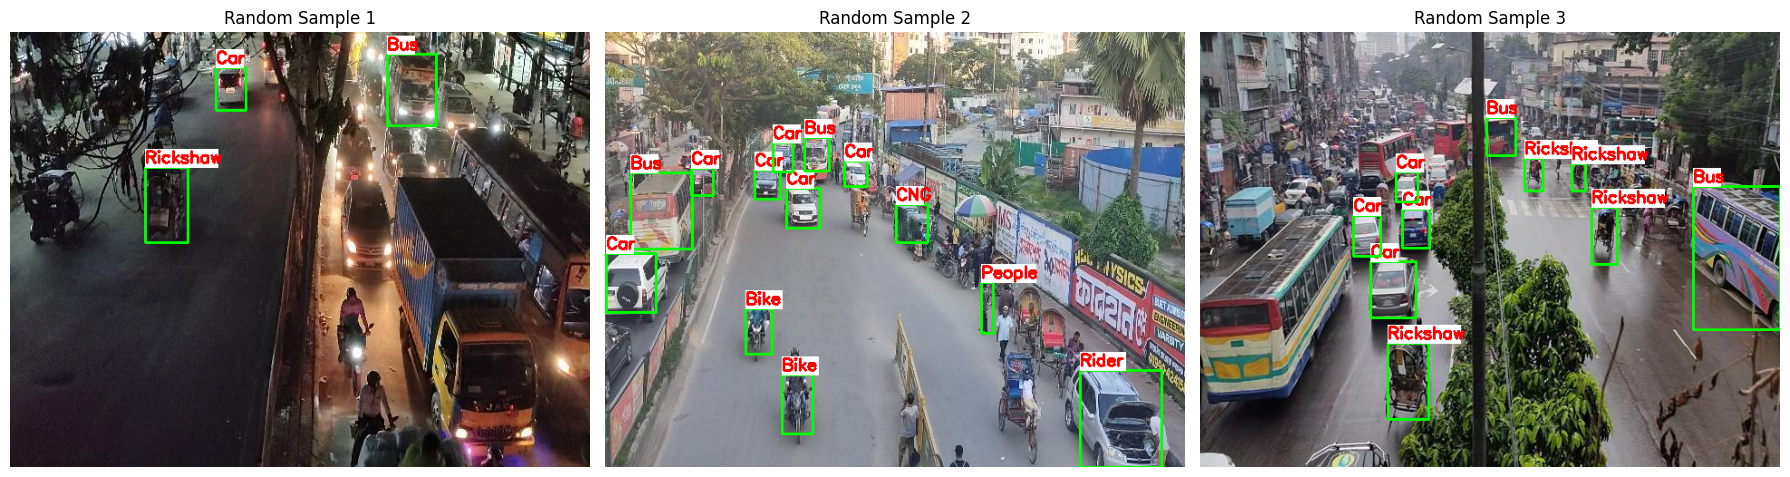

✅ Sanity Check complete. Review the plotted images above.


In [ ]:
import yaml
import os
import random
import cv2
import matplotlib.pyplot as plt

print("🔍 Initiating Visual Sanity Check using Dhaka_Traffic.yaml...")

# 1. Load the YAML map
yaml_path = '/content/drive/MyDrive/Thesis/Version 6/Dhaka_Traffic.yaml'
with open(yaml_path, 'r') as f:
    data = yaml.safe_load(f)

base_path = data['path']
train_img_dir = os.path.join(base_path, data['train'])
train_lbl_dir = train_img_dir.replace('images', 'labels') # YOLO expects labels in a matching sibling folder
class_names = data['names']

# 2. Pick 3 random images
all_images = [f for f in os.listdir(train_img_dir) if f.endswith(('.jpg', '.jpeg', '.png'))]
sample_images = random.sample(all_images, 3)

plt.figure(figsize=(18, 6))

# 3. Draw the boxes and YAML names
for i, img_name in enumerate(sample_images):
    img_path = os.path.join(train_img_dir, img_name)
    lbl_path = os.path.join(train_lbl_dir, os.path.splitext(img_name)[0] + '.txt')

    # Read the image
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    # Read the text file and draw boxes
    if os.path.exists(lbl_path):
        with open(lbl_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    class_id = int(parts[0])
                    x_center, y_center, width, height = map(float, parts[1:])

                    # Convert YOLO decimals to actual pixels
                    x1 = int((x_center - width / 2) * w)
                    y1 = int((y_center - height / 2) * h)
                    x2 = int((x_center + width / 2) * w)
                    y2 = int((y_center + height / 2) * h)

                    # Draw Box (Green)
                    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)

                    # Draw YAML Class Name (Red text on white background for readability)
                    label_text = class_names[class_id]
                    cv2.rectangle(img, (x1, y1-20), (x1 + len(label_text)*10, y1), (255, 255, 255), -1)
                    cv2.putText(img, label_text, (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

    # Plot the image
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Random Sample {i+1}")

plt.tight_layout()
plt.show()

print("✅ Sanity Check complete. Review the plotted images above.")

## The Surgical Merge

In [ ]:
import os
import yaml
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

print("⚙️ INITIATING SURGICAL MERGE...")

# 1. PATHS
base_lbl_dir = '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset/labels'
splits = ['train', 'val', 'test']

# 2. THE REMAPPING DICTIONARY
# 0-4 stay the same. 5 (Rider) and 6 (People) both become 5. 7 becomes 6, 8 becomes 7.
id_map = {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 5, 7: 6, 8: 7}

def process_file(file_path):
    with open(file_path, 'r') as f:
        lines = f.readlines()

    new_lines = []
    modified = False
    for line in lines:
        parts = line.strip().split()
        if len(parts) == 5:
            old_id = int(parts[0])
            if old_id in id_map:
                new_id = id_map[old_id]
                if new_id != old_id:
                    modified = True
                new_lines.append(f"{new_id} {' '.join(parts[1:])}\n")

    # Only rewrite if a change was actually needed
    if modified:
        with open(file_path, 'w') as f:
            f.writelines(new_lines)

# 3. MULTI-THREADED FILE REWRITING
all_label_files = []
for split in splits:
    split_dir = os.path.join(base_lbl_dir, split)
    all_label_files.extend([os.path.join(split_dir, f) for f in os.listdir(split_dir) if f.endswith('.txt')])

print(f"🔍 Found {len(all_label_files):,} label files. Re-mapping IDs...")
with ThreadPoolExecutor(max_workers=32) as executor:
    list(tqdm(executor.map(process_file, all_label_files), total=len(all_label_files), desc="Surgical Merge"))

# 4. UPDATING THE YAML FILE
yaml_path = '/content/drive/MyDrive/Thesis/Version 6/Dhaka_Traffic.yaml'
data_yaml = {
    'path': '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset',
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'nc': 8,  # Now 8 classes instead of 9
    'names': {
        0: 'Bike',
        1: 'Bus',
        2: 'Car',
        3: 'CNG',
        4: 'Cycle',
        5: 'People',   # Merged!
        6: 'Rickshaw', # Shifted down
        7: 'Truck'     # Shifted down
    }
}

with open(yaml_path, 'w') as f:
    yaml.dump(data_yaml, f, sort_keys=False)

print("\n✅ SURGICAL MERGE COMPLETE! YAML updated to 8 continuous classes.")

⚙️ INITIATING SURGICAL MERGE...
🔍 Found 32,306 label files. Re-mapping IDs...


Surgical Merge: 100%|██████████| 32306/32306 [18:21<00:00, 29.33it/s]


✅ SURGICAL MERGE COMPLETE! YAML updated to 8 continuous classes.


In [ ]:
import os
from datetime import datetime
import pytz

dhaka_tz = pytz.timezone('Asia/Dhaka')
tracker_path = '/content/drive/MyDrive/Thesis/Version 6/Thesis_Progress_Tracker.txt'

def update_progress(task_description):
    now = datetime.now(dhaka_tz).strftime("%Y-%m-%d %I:%M:%S %p")
    with open(tracker_path, 'a') as f:
        f.write(f"[{now}] {task_description}\n")
    print(f"✅ Logged to Tracker: {task_description}")

update_progress("Phase 2.1 Complete: Surgical Merge successfully remapped 32,306 files. 'Rider' merged into 'People'. YAML updated to 8 continuous classes.")

✅ Logged to Tracker: Phase 2.1 Complete: Surgical Merge successfully remapped 32,306 files. 'Rider' merged into 'People'. YAML updated to 8 continuous classes.


## The Ultimate Visual Verification

🔍 Hunting for 2 verification images per class...


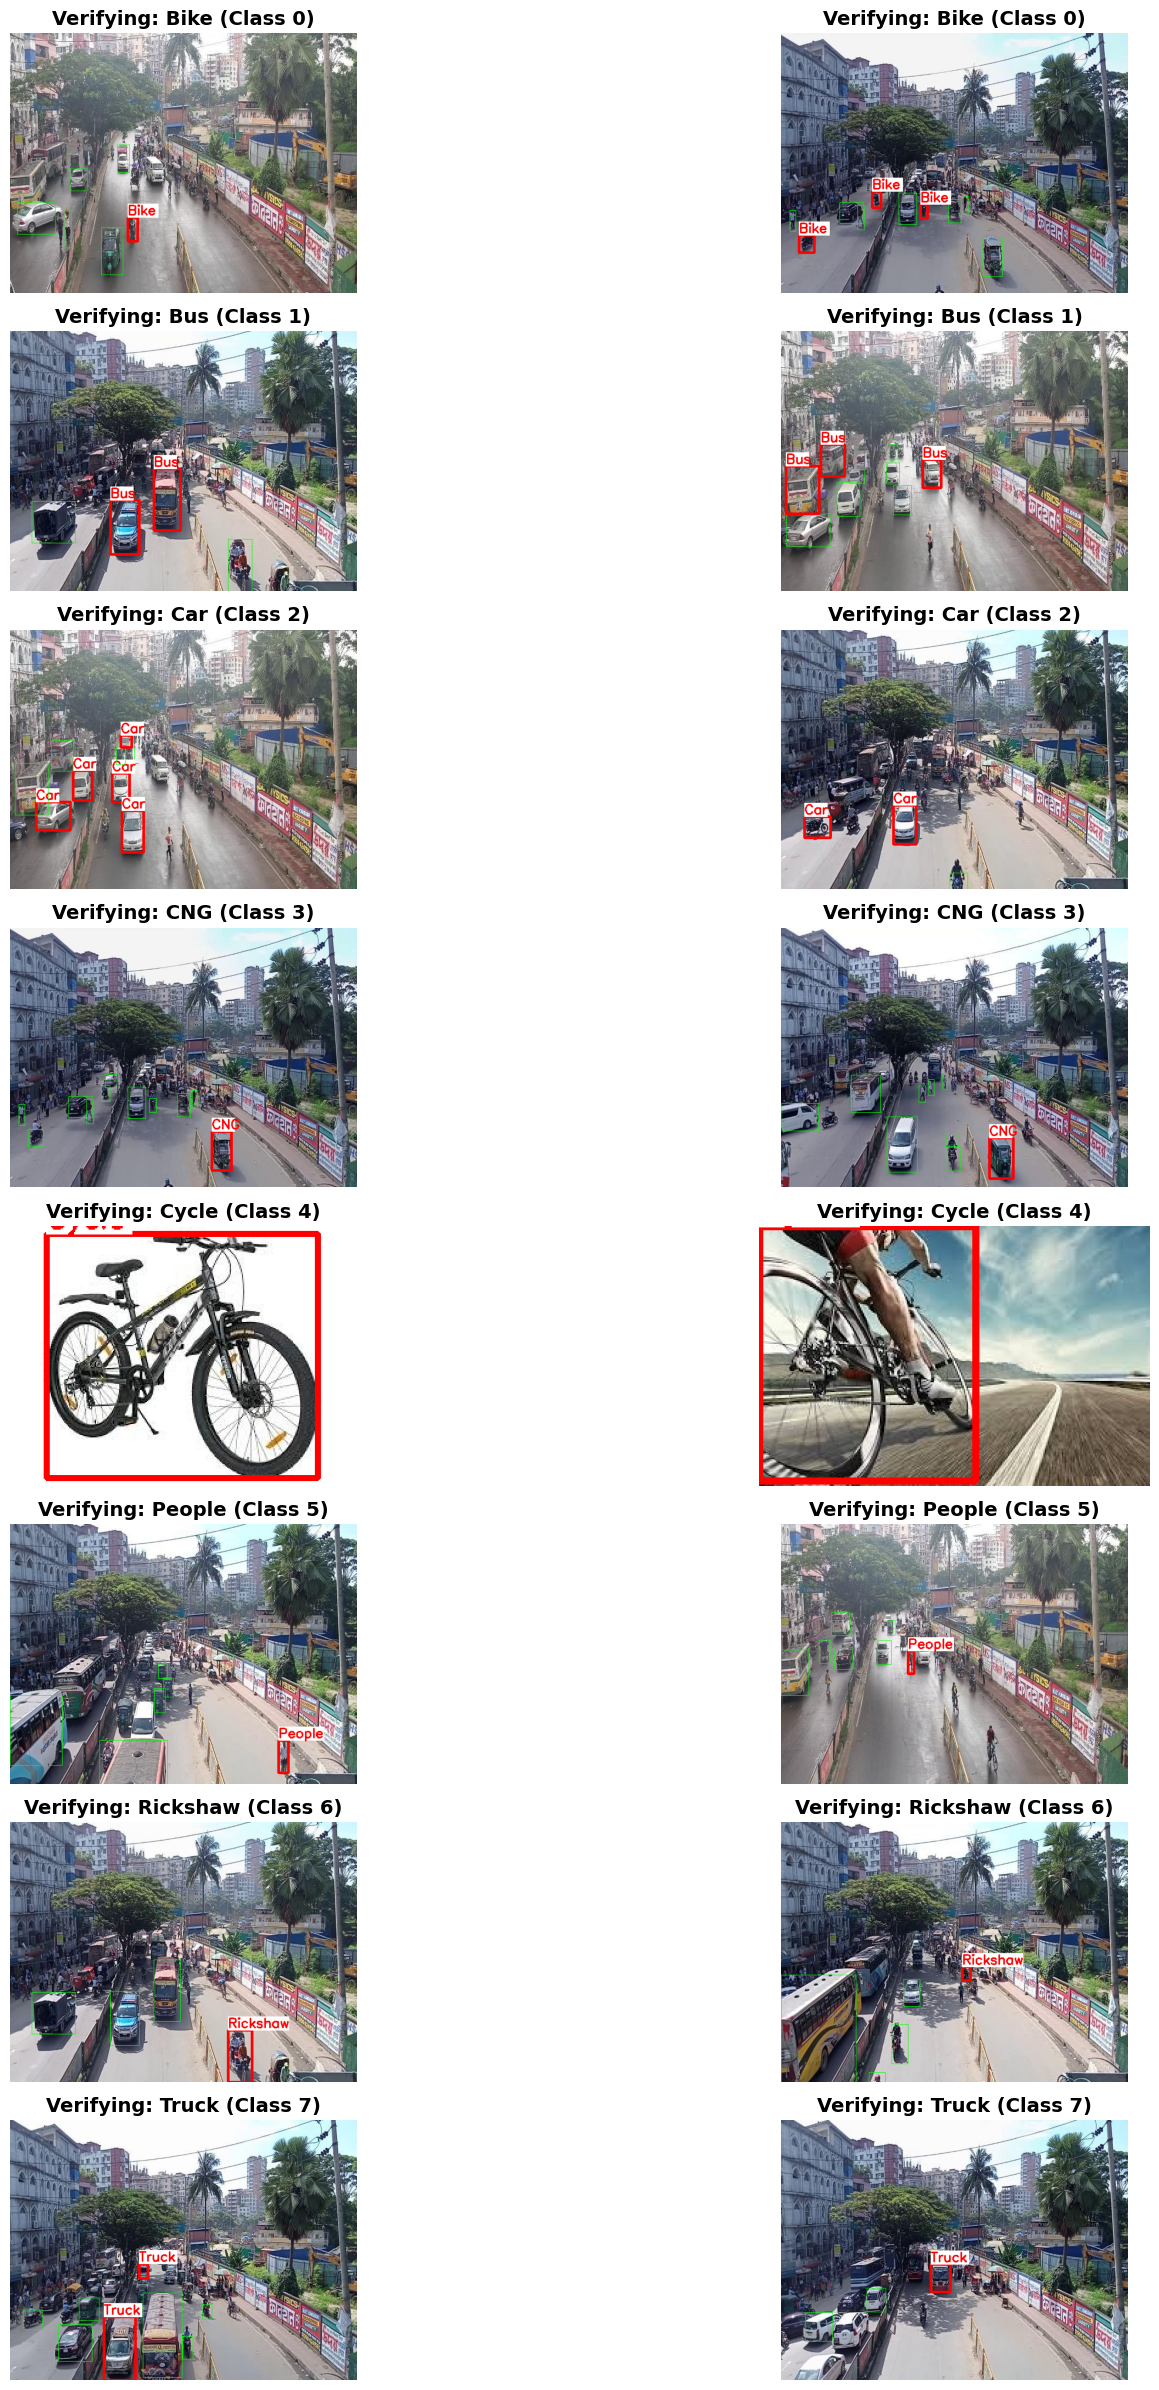

✅ Sanity Check complete. Review the plotted images above.


In [ ]:
import yaml
import os
import random
import cv2
import matplotlib.pyplot as plt

print("🔍 Hunting for 2 verification images per class...")

# Load the updated YAML map
yaml_path = '/content/drive/MyDrive/Thesis/Version 6/Dhaka_Traffic.yaml'
with open(yaml_path, 'r') as f:
    data = yaml.safe_load(f)

train_lbl_dir = os.path.join(data['path'], data['train'].replace('images', 'labels'))
train_img_dir = os.path.join(data['path'], data['train'])
class_names = data['names']

# Dictionary to store file paths that contain a specific class
class_image_inventory = {i: [] for i in range(8)}

# Scan labels until we have enough examples of each class
for txt in os.listdir(train_lbl_dir):
    if not txt.endswith('.txt'): continue

    with open(os.path.join(train_lbl_dir, txt), 'r') as f:
        found_classes_in_file = set()
        for line in f:
            found_classes_in_file.add(int(line.split()[0]))

    for cid in found_classes_in_file:
        if len(class_image_inventory[cid]) < 20: # Buffer of 20 images
            class_image_inventory[cid].append(txt)

# Plotting
plt.figure(figsize=(20, 24))

plot_idx = 1
for cid in range(8):
    # Grab 2 random images for this specific class
    sample_txts = random.sample(class_image_inventory[cid], 2)

    for txt_name in sample_txts:
        img_name = os.path.splitext(txt_name)[0]
        # Find the correct image extension
        for ext in ['.jpg', '.jpeg', '.png']:
            img_path = os.path.join(train_img_dir, img_name + ext)
            if os.path.exists(img_path): break

        lbl_path = os.path.join(train_lbl_dir, txt_name)

        # Read and convert image
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape

        # Draw boxes
        with open(lbl_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    box_cid = int(parts[0])
                    x_c, y_c, bw, bh = map(float, parts[1:])

                    x1, y1 = int((x_c - bw / 2) * w), int((y_c - bh / 2) * h)
                    x2, y2 = int((x_c + bw / 2) * w), int((y_c + bh / 2) * h)

                    # Highlight the specific class we are verifying in RED, others in GREEN
                    color = (255, 0, 0) if box_cid == cid else (0, 255, 0)
                    thickness = 3 if box_cid == cid else 1
                    cv2.rectangle(img, (x1, y1), (x2, y2), color, thickness)

                    if box_cid == cid: # Only put text on the target class to avoid clutter
                        label_text = class_names[box_cid]
                        cv2.rectangle(img, (x1, y1-25), (x1 + len(label_text)*14, y1), (255, 255, 255), -1)
                        cv2.putText(img, label_text, (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)

        plt.subplot(8, 2, plot_idx)
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"Verifying: {class_names[cid]} (Class {cid})", fontsize=14, weight='bold')
        plot_idx += 1

plt.tight_layout()
plt.show()

print("✅ Sanity Check complete. Review the plotted images above.")

In [ ]:
import yaml

yaml_path = '/content/drive/MyDrive/Thesis/Version 6/Dhaka_Traffic.yaml'
data_yaml = {
    'path': '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset',
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'nc': 8,
    'names': {
        0: 'Bike',
        1: 'Bus/Microbus', # Updated per your instruction!
        2: 'Car',
        3: 'CNG',
        4: 'Cycle',
        5: 'People',
        6: 'Rickshaw',
        7: 'Truck'
    }
}

with open(yaml_path, 'w') as f:
    yaml.dump(data_yaml, f, sort_keys=False)
print("✅ YAML Updated: Class 1 is now 'Bus/Microbus'.")

✅ YAML Updated: Class 1 is now 'Bus/Microbus'.


# GNITION (Phase 2.1 - Dhaka Baseline Training)

In [ ]:
from ultralytics import YOLO

print("🚀 Emergency Pivot: Launching Baseline directly from Google Drive...")

model = YOLO('yolo26m.pt')

print("🔥 Initiating Phase 2.1: Training Baseline on Dhaka Traffic...")
results = model.train(
    data='/content/drive/MyDrive/Thesis/Version 6/Dhaka_Traffic.yaml', # The original Drive map
    epochs=50,
    imgsz=640,
    batch=16,
    project='/content/drive/MyDrive/Thesis/Version 6/Training_Runs',
    name='Dhaka_YOLO26m_Baseline',
    patience=10,
    save=True,
    device=0
)

🚀 Emergency Pivot: Launching Baseline directly from Google Drive...
🔥 Initiating Phase 2.1: Training Baseline on Dhaka Traffic...
Ultralytics 8.4.40 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Thesis/Version 6/Dhaka_Traffic.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m.

In [ ]:
import os
import shutil
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
import yaml

drive_dir = '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset'
local_dir = '/content/Master_Dataset_Local'

print("🚀 Initiating Multi-Threaded Lightning Transfer to Local SSD...")

# 1. Map all files
files_to_copy = []
for root, _, files in os.walk(drive_dir):
    for file in files:
        src_path = os.path.join(root, file)
        dst_path = src_path.replace(drive_dir, local_dir)
        files_to_copy.append((src_path, dst_path))

# 2. Create target folders instantly
for _, dst_path in files_to_copy:
    os.makedirs(os.path.dirname(dst_path), exist_ok=True)

# 3. Multi-threaded copy engine
def copy_file(paths):
    src, dst = paths
    if not os.path.exists(dst):
        shutil.copy2(src, dst)

print(f"📦 Found {len(files_to_copy):,} files. Transferring with 32 parallel threads...")
with ThreadPoolExecutor(max_workers=32) as executor:
    list(tqdm(executor.map(copy_file, files_to_copy), total=len(files_to_copy), desc="Transferring Data"))

print("✅ Local transfer complete!")

# 4. Build the Local YAML Map (Forcing nc=8 to fix yesterday's glitch)
print("⚙️ Building the Local YOLO configuration file...")
local_yaml_path = '/content/Dhaka_Traffic_Local.yaml'

data_yaml = {
    'path': local_dir,
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'nc': 8,
    'names': {
        0: 'Bike',
        1: 'Bus/Microbus',
        2: 'Car',
        3: 'CNG',
        4: 'Cycle',
        5: 'People',
        6: 'Rickshaw',
        7: 'Truck'
    }
}

with open(local_yaml_path, 'w') as f:
    yaml.dump(data_yaml, f, sort_keys=False)

print(f"✅ Fast Map created at: {local_yaml_path}")

🚀 Initiating Multi-Threaded Lightning Transfer to Local SSD...
📦 Found 64,615 files. Transferring with 32 parallel threads...


Transferring Data: 100%|██████████| 64615/64615 [25:34<00:00, 42.10it/s]

✅ Local transfer complete!
⚙️ Building the Local YOLO configuration file...
✅ Fast Map created at: /content/Dhaka_Traffic_Local.yaml


In [ ]:
from ultralytics import YOLO

print("🚀 Waking up the YOLO26m Baseline Model...")
model = YOLO('yolo26m.pt')

print("🔥 Initiating Phase 2.1: Training Baseline on LOCAL Dhaka Traffic...")
results = model.train(
    data='/content/Dhaka_Traffic_Local.yaml', # Using our lightning-fast local map!
    epochs=50,
    imgsz=640,
    batch=16,
    project='/content/drive/MyDrive/Thesis/Version 6/Training_Runs', # Still safely auto-saving to Drive!
    name='Dhaka_YOLO26m_Baseline',
    patience=10,
    save=True,
    device=0
)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
🚀 Waking up the YOLO26m Baseline Model...
🔥 Initiating Phase 2.1: Training Baseline on LOCAL Dhaka Traffic...
Ultralytics 8.4.41 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Dhaka_Traffic_Local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0

In [ ]:
  import os
import shutil
import yaml
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
from ultralytics import YOLO

print("🛡️ INITIATING BULLETPROOF RESUME PROTOCOL...")

# 1. Satisfy YOLO's memory (Create the exact map it demands)
local_yaml_path = '/content/Dhaka_Traffic_Local.yaml'
with open(local_yaml_path, 'w') as f:
    yaml.dump({
        'path': '/content/Master_Dataset_Local',
        'train': 'images/train',
        'val': 'images/val',
        'test': 'images/test',
        'nc': 8,
        'names': {0: 'Bike', 1: 'Bus/Microbus', 2: 'Car', 3: 'CNG', 4: 'Cycle', 5: 'People', 6: 'Rickshaw', 7: 'Truck'}
    }, f, sort_keys=False)
print("✅ Configuration map locked and loaded.")

# 2. Smart Transfer Engine
drive_dir = '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset'
local_dir = '/content/Master_Dataset_Local'

# Check if data is already here from a previous run today
if not os.path.exists(os.path.join(local_dir, 'images', 'train')):
    print("📂 Local data missing (Server wiped). Initiating high-speed transfer from Drive...")
    files_to_copy = []
    for root, _, files in os.walk(drive_dir):
        for file in files:
            src_path = os.path.join(root, file)
            dst_path = src_path.replace(drive_dir, local_dir)
            files_to_copy.append((src_path, dst_path))

    for _, dst_path in files_to_copy:
        os.makedirs(os.path.dirname(dst_path), exist_ok=True)

    def copy_file(paths):
        src, dst = paths
        if not os.path.exists(dst):
            shutil.copy2(src, dst)

    with ThreadPoolExecutor(max_workers=32) as executor:
        list(tqdm(executor.map(copy_file, files_to_copy), total=len(files_to_copy), desc="Transferring Data"))
    print("✅ High-speed transfer complete.")
else:
    print("⚡ Local data already exists! Skipping transfer to save time.")

# 3. Automatic Resume
print("🚀 Waking up YOLO and Resuming Training from last checkpoint...")
model = YOLO('/content/drive/MyDrive/Thesis/Version 6/Training_Runs/Dhaka_YOLO26m_Baseline-4/weights/last.pt')
results = model.train(resume=True)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
🛡️ INITIATING BULLETPROOF RESUME PROTOCOL...
✅ Configuration map locked and loaded.
📂 Local data missing (Server wiped). Initiating high-speed transfer from Drive...


Transferring Data: 100%|██████████| 64615/64615 [30:21<00:00, 35.47it/s]


✅ High-speed transfer complete.
🚀 Waking up YOLO and Resuming Training from last checkpoint...
Ultralytics 8.4.41 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Dhaka_Traffic_Local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/Thesis/Version 6/Training_Runs/Dhaka_YOLO26m_

In [ ]:
  import os
import shutil
import yaml
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
from ultralytics import YOLO

print("🛡️ INITIATING BULLETPROOF RESUME PROTOCOL...")

# 1. Satisfy YOLO's memory (Create the exact map it demands)
local_yaml_path = '/content/Dhaka_Traffic_Local.yaml'
with open(local_yaml_path, 'w') as f:
    yaml.dump({
        'path': '/content/Master_Dataset_Local',
        'train': 'images/train',
        'val': 'images/val',
        'test': 'images/test',
        'nc': 8,
        'names': {0: 'Bike', 1: 'Bus/Microbus', 2: 'Car', 3: 'CNG', 4: 'Cycle', 5: 'People', 6: 'Rickshaw', 7: 'Truck'}
    }, f, sort_keys=False)
print("✅ Configuration map locked and loaded.")

# 2. Smart Transfer Engine
drive_dir = '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset'
local_dir = '/content/Master_Dataset_Local'

# Check if data is already here from a previous run today
if not os.path.exists(os.path.join(local_dir, 'images', 'train')):
    print("📂 Local data missing (Server wiped). Initiating high-speed transfer from Drive...")
    files_to_copy = []
    for root, _, files in os.walk(drive_dir):
        for file in files:
            src_path = os.path.join(root, file)
            dst_path = src_path.replace(drive_dir, local_dir)
            files_to_copy.append((src_path, dst_path))

    for _, dst_path in files_to_copy:
        os.makedirs(os.path.dirname(dst_path), exist_ok=True)

    def copy_file(paths):
        src, dst = paths
        if not os.path.exists(dst):
            shutil.copy2(src, dst)

    with ThreadPoolExecutor(max_workers=32) as executor:
        list(tqdm(executor.map(copy_file, files_to_copy), total=len(files_to_copy), desc="Transferring Data"))
    print("✅ High-speed transfer complete.")
else:
    print("⚡ Local data already exists! Skipping transfer to save time.")

# 3. Automatic Resume
print("🚀 Waking up YOLO and Resuming Training from last checkpoint...")
model = YOLO('/content/drive/MyDrive/Thesis/Version 6/Training_Runs/Dhaka_YOLO26m_Baseline-4/weights/last.pt')
results = model.train(resume=True)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
🛡️ INITIATING BULLETPROOF RESUME PROTOCOL...
✅ Configuration map locked and loaded.
📂 Local data missing (Server wiped). Initiating high-speed transfer from Drive...


Transferring Data: 100%|██████████| 64615/64615 [24:46<00:00, 43.48it/s]


✅ High-speed transfer complete.
🚀 Waking up YOLO and Resuming Training from last checkpoint...
Ultralytics 8.4.41 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Dhaka_Traffic_Local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/Thesis/Version 6/Training_Runs/Dhaka_YOLO26m_

In [ ]:
  import os
import shutil
import yaml
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
from ultralytics import YOLO

print("🛡️ INITIATING BULLETPROOF RESUME PROTOCOL...")

# 1. Satisfy YOLO's memory (Create the exact map it demands)
local_yaml_path = '/content/Dhaka_Traffic_Local.yaml'
with open(local_yaml_path, 'w') as f:
    yaml.dump({
        'path': '/content/Master_Dataset_Local',
        'train': 'images/train',
        'val': 'images/val',
        'test': 'images/test',
        'nc': 8,
        'names': {0: 'Bike', 1: 'Bus/Microbus', 2: 'Car', 3: 'CNG', 4: 'Cycle', 5: 'People', 6: 'Rickshaw', 7: 'Truck'}
    }, f, sort_keys=False)
print("✅ Configuration map locked and loaded.")

# 2. Smart Transfer Engine
drive_dir = '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset'
local_dir = '/content/Master_Dataset_Local'

# Check if data is already here from a previous run today
if not os.path.exists(os.path.join(local_dir, 'images', 'train')):
    print("📂 Local data missing (Server wiped). Initiating high-speed transfer from Drive...")
    files_to_copy = []
    for root, _, files in os.walk(drive_dir):
        for file in files:
            src_path = os.path.join(root, file)
            dst_path = src_path.replace(drive_dir, local_dir)
            files_to_copy.append((src_path, dst_path))

    for _, dst_path in files_to_copy:
        os.makedirs(os.path.dirname(dst_path), exist_ok=True)

    def copy_file(paths):
        src, dst = paths
        if not os.path.exists(dst):
            shutil.copy2(src, dst)

    with ThreadPoolExecutor(max_workers=32) as executor:
        list(tqdm(executor.map(copy_file, files_to_copy), total=len(files_to_copy), desc="Transferring Data"))
    print("✅ High-speed transfer complete.")
else:
    print("⚡ Local data already exists! Skipping transfer to save time.")

# 3. Automatic Resume
print("🚀 Waking up YOLO and Resuming Training from last checkpoint...")
model = YOLO('/content/drive/MyDrive/Thesis/Version 6/Training_Runs/Dhaka_YOLO26m_Baseline-4/weights/last.pt')
results = model.train(resume=True)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
🛡️ INITIATING BULLETPROOF RESUME PROTOCOL...
✅ Configuration map locked and loaded.
📂 Local data missing (Server wiped). Initiating high-speed transfer from Drive...


Transferring Data: 100%|██████████| 64615/64615 [29:51<00:00, 36.07it/s]


✅ High-speed transfer complete.
🚀 Waking up YOLO and Resuming Training from last checkpoint...
Ultralytics 8.4.42 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Dhaka_Traffic_Local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/Thesis/Version 6/Training_Runs/Dhaka_YOLO26m_

In [ ]:
  import os
import shutil
import yaml
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
from ultralytics import YOLO

print("🛡️ INITIATING BULLETPROOF RESUME PROTOCOL...")

# 1. Satisfy YOLO's memory (Create the exact map it demands)
local_yaml_path = '/content/Dhaka_Traffic_Local.yaml'
with open(local_yaml_path, 'w') as f:
    yaml.dump({
        'path': '/content/Master_Dataset_Local',
        'train': 'images/train',
        'val': 'images/val',
        'test': 'images/test',
        'nc': 8,
        'names': {0: 'Bike', 1: 'Bus/Microbus', 2: 'Car', 3: 'CNG', 4: 'Cycle', 5: 'People', 6: 'Rickshaw', 7: 'Truck'}
    }, f, sort_keys=False)
print("✅ Configuration map locked and loaded.")

# 2. Smart Transfer Engine
drive_dir = '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset'
local_dir = '/content/Master_Dataset_Local'

# Check if data is already here from a previous run today
if not os.path.exists(os.path.join(local_dir, 'images', 'train')):
    print("📂 Local data missing (Server wiped). Initiating high-speed transfer from Drive...")
    files_to_copy = []
    for root, _, files in os.walk(drive_dir):
        for file in files:
            src_path = os.path.join(root, file)
            dst_path = src_path.replace(drive_dir, local_dir)
            files_to_copy.append((src_path, dst_path))

    for _, dst_path in files_to_copy:
        os.makedirs(os.path.dirname(dst_path), exist_ok=True)

    def copy_file(paths):
        src, dst = paths
        if not os.path.exists(dst):
            shutil.copy2(src, dst)

    with ThreadPoolExecutor(max_workers=32) as executor:
        list(tqdm(executor.map(copy_file, files_to_copy), total=len(files_to_copy), desc="Transferring Data"))
    print("✅ High-speed transfer complete.")
else:
    print("⚡ Local data already exists! Skipping transfer to save time.")

# 3. Automatic Resume
print("🚀 Waking up YOLO and Resuming Training from last checkpoint...")
model = YOLO('/content/drive/MyDrive/Thesis/Version 6/Training_Runs/Dhaka_YOLO26m_Baseline-4/weights/last.pt')
results = model.train(resume=True)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
🛡️ INITIATING BULLETPROOF RESUME PROTOCOL...
✅ Configuration map locked and loaded.
📂 Local data missing (Server wiped). Initiating high-speed transfer from Drive...


Transferring Data: 100%|██████████| 64615/64615 [26:22<00:00, 40.84it/s]


✅ High-speed transfer complete.
🚀 Waking up YOLO and Resuming Training from last checkpoint...
Ultralytics 8.4.43 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Dhaka_Traffic_Local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/Thesis/Version 6/Training_Runs/Dhaka_YOLO26m_

In [ ]:
  import os
import shutil
import yaml
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
from ultralytics import YOLO

print("🛡️ INITIATING BULLETPROOF RESUME PROTOCOL...")

# 1. Satisfy YOLO's memory (Create the exact map it demands)
local_yaml_path = '/content/Dhaka_Traffic_Locaal.yaml'
with open(local_yaml_path, 'w') as f:
    yaml.dump({
        'path': '/content/Master_Dataset_Local',
        'train': 'images/train',
        'val': 'images/val',
        'test': 'images/test',
        'nc': 8,
        'names': {0: 'Bike', 1: 'Bus/Microbus', 2: 'Car', 3: 'CNG', 4: 'Cycle', 5: 'People', 6: 'Rickshaw', 7: 'Truck'}
    }, f, sort_keys=False)
print("✅ Configuration map locked and loaded.")

# 2. Smart Transfer Engine
drive_dir = '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset'
local_dir = '/content/Master_Dataset_Local'

# Check if data is already here from a previous run today
if not os.path.exists(os.path.join(local_dir, 'images', 'train')):
    print("📂 Local data missing (Server wiped). Initiating high-speed transfer from Drive...")
    files_to_copy = []
    for root, _, files in os.walk(drive_dir):
        for file in files:
            src_path = os.path.join(root, file)
            dst_path = src_path.replace(drive_dir, local_dir)
            files_to_copy.append((src_path, dst_path))

    for _, dst_path in files_to_copy:
        os.makedirs(os.path.dirname(dst_path), exist_ok=True)

    def copy_file(paths):
        src, dst = paths
        if not os.path.exists(dst):
            shutil.copy2(src, dst)

    with ThreadPoolExecutor(max_workers=32) as executor:
        list(tqdm(executor.map(copy_file, files_to_copy), total=len(files_to_copy), desc="Transferring Data"))
    print("✅ High-speed transfer complete.")
else:
    print("⚡ Local data already exists! Skipping transfer to save time.")

# 3. Automatic Resume
print("🚀 Waking up YOLO and Resuming Training from last checkpoint...")
model = YOLO('/content/drive/MyDrive/Thesis/Version 6/Training_Runs/Dhaka_YOLO26m_Baseline-4/weights/last.pt')
results = model.train(resume=True)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
🛡️ INITIATING BULLETPROOF RESUME PROTOCOL...
✅ Configuration map locked and loaded.
📂 Local data missing (Server wiped). Initiating high-speed transfer from Drive...


Transferring Data: 100%|██████████| 64615/64615 [27:19<00:00, 39.41it/s]


✅ High-speed transfer complete.
🚀 Waking up YOLO and Resuming Training from last checkpoint...
Ultralytics 8.4.45 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Dhaka_Traffic_Local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/Thesis/Version 6/Training_Runs/Dhaka_YOLO26m_

In [ ]:
import os
import shutil
import yaml
import torch
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
from ultralytics import YOLO

print("🛡️ INITIATING SURGICAL RESUME PROTOCOL...")

# 1. Satisfy YOLO's memory (Create the exact map it demands)
local_yaml_path = '/content/Dhaka_Traffic_Local.yaml'
with open(local_yaml_path, 'w') as f:
    yaml.dump({
        'path': '/content/Master_Dataset_Local',
        'train': 'images/train',
        'val': 'images/val',
        'test': 'images/test',
        'nc': 8,
        'names': {0: 'Bike', 1: 'Bus/Microbus', 2: 'Car', 3: 'CNG', 4: 'Cycle', 5: 'People', 6: 'Rickshaw', 7: 'Truck'}
    }, f, sort_keys=False)
print("✅ Configuration map locked and loaded.")

# 2. Smart Transfer Engine
drive_dir = '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset'
local_dir = '/content/Master_Dataset_Local'

if not os.path.exists(os.path.join(local_dir, 'images', 'train')):
    print("📂 Local data missing. Initiating high-speed transfer from Drive...")
    files_to_copy = []
    for root, _, files in os.walk(drive_dir):
        for file in files:
            src_path = os.path.join(root, file)
            dst_path = src_path.replace(drive_dir, local_dir)
            files_to_copy.append((src_path, dst_path))

    for _, dst_path in files_to_copy:
        os.makedirs(os.path.dirname(dst_path), exist_ok=True)

    def copy_file(paths):
        src, dst = paths
        if not os.path.exists(dst):
            shutil.copy2(src, dst)

    with ThreadPoolExecutor(max_workers=32) as executor:
        list(tqdm(executor.map(copy_file, files_to_copy), total=len(files_to_copy), desc="Transferring Data"))
    print("✅ High-speed transfer complete.")
else:
    print("⚡ Local data already exists! Skipping transfer to save time.")

# 3. BRAIN SURGERY (Fixing the COCO8 Glitch)
run_dir = '/content/drive/MyDrive/Thesis/Version 6/Training_Runs/Dhaka_YOLO26m_Baseline-4'
args_file = os.path.join(run_dir, 'args.yaml')
ckpt_file = os.path.join(run_dir, 'weights', 'last.pt')

print("🧠 Performing amnesia surgery on config files...")

# Fix args.yaml in Google Drive
if os.path.exists(args_file):
    with open(args_file, 'r') as f:
        args = yaml.safe_load(f)
    if args.get('data') != local_yaml_path:
        args['data'] = local_yaml_path
        with open(args_file, 'w') as f:
            yaml.dump(args, f)
        print("   -> args.yaml repaired.")

# Fix last.pt internal memory in Google Drive
if os.path.exists(ckpt_file):
    ckpt = torch.load(ckpt_file, map_location='cpu', weights_only=False)
    if 'train_args' in ckpt and ckpt['train_args'].get('data') != local_yaml_path:
        ckpt['train_args']['data'] = local_yaml_path
        torch.save(ckpt, ckpt_file)
        print("   -> last.pt internal memory repaired.")
print("✅ Surgery complete. YOLO knows it is in Dhaka now.")

# 4. Automatic Resume
print("🚀 Waking up YOLO and Resuming Training from Epoch 38...")
model = YOLO(ckpt_file)
results = model.train(resume=True)

🛡️ INITIATING SURGICAL RESUME PROTOCOL...
✅ Configuration map locked and loaded.
⚡ Local data already exists! Skipping transfer to save time.
🧠 Performing amnesia surgery on config files...
   -> args.yaml repaired.
✅ Surgery complete. YOLO knows it is in Dhaka now.
🚀 Waking up YOLO and Resuming Training from Epoch 38...
Ultralytics 8.4.45 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Dhaka_Traffic_Local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7,

In [ ]:
import os
import shutil
import yaml
import torch
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
from ultralytics import YOLO

print("🛡️ INITIATING SURGICAL RESUME PROTOCOL...")

# 1. Satisfy YOLO's memory (Create the exact map it demands)
local_yaml_path = '/content/Dhaka_Traffic_Local.yaml'
with open(local_yaml_path, 'w') as f:
    yaml.dump({
        'path': '/content/Master_Dataset_Local',
        'train': 'images/train',
        'val': 'images/val',
        'test': 'images/test',
        'nc': 8,
        'names': {0: 'Bike', 1: 'Bus/Microbus', 2: 'Car', 3: 'CNG', 4: 'Cycle', 5: 'People', 6: 'Rickshaw', 7: 'Truck'}
    }, f, sort_keys=False)
print("✅ Configuration map locked and loaded.")

# 2. Smart Transfer Engine
drive_dir = '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset'
local_dir = '/content/Master_Dataset_Local'

if not os.path.exists(os.path.join(local_dir, 'images', 'train')):
    print("📂 Local data missing. Initiating high-speed transfer from Drive...")
    files_to_copy = []
    for root, _, files in os.walk(drive_dir):
        for file in files:
            src_path = os.path.join(root, file)
            dst_path = src_path.replace(drive_dir, local_dir)
            files_to_copy.append((src_path, dst_path))

    for _, dst_path in files_to_copy:
        os.makedirs(os.path.dirname(dst_path), exist_ok=True)

    def copy_file(paths):
        src, dst = paths
        if not os.path.exists(dst):
            shutil.copy2(src, dst)

    with ThreadPoolExecutor(max_workers=32) as executor:
        list(tqdm(executor.map(copy_file, files_to_copy), total=len(files_to_copy), desc="Transferring Data"))
    print("✅ High-speed transfer complete.")
else:
    print("⚡ Local data already exists! Skipping transfer to save time.")

# 3. BRAIN SURGERY (Fixing the COCO8 Glitch)
run_dir = '/content/drive/MyDrive/Thesis/Version 6/Training_Runs/Dhaka_YOLO26m_Baseline-4'
args_file = os.path.join(run_dir, 'args.yaml')
ckpt_file = os.path.join(run_dir, 'weights', 'last.pt')

print("🧠 Performing amnesia surgery on config files...")

# Fix args.yaml in Google Drive
if os.path.exists(args_file):
    with open(args_file, 'r') as f:
        args = yaml.safe_load(f)
    if args.get('data') != local_yaml_path:
        args['data'] = local_yaml_path
        with open(args_file, 'w') as f:
            yaml.dump(args, f)
        print("   -> args.yaml repaired.")

# Fix last.pt internal memory in Google Drive
if os.path.exists(ckpt_file):
    ckpt = torch.load(ckpt_file, map_location='cpu', weights_only=False)
    if 'train_args' in ckpt and ckpt['train_args'].get('data') != local_yaml_path:
        ckpt['train_args']['data'] = local_yaml_path
        torch.save(ckpt, ckpt_file)
        print("   -> last.pt internal memory repaired.")
print("✅ Surgery complete. YOLO knows it is in Dhaka now.")

# 4. Automatic Resume
print("🚀 Waking up YOLO and Resuming Training from Epoch 38...")
model = YOLO(ckpt_file)
results = model.train(resume=True)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
🛡️ INITIATING SURGICAL RESUME PROTOCOL...
✅ Configuration map locked and loaded.
📂 Local data missing. Initiating high-speed transfer from Drive...


Transferring Data: 100%|██████████| 64615/64615 [22:41<00:00, 47.45it/s]


✅ High-speed transfer complete.
🧠 Performing amnesia surgery on config files...
✅ Surgery complete. YOLO knows it is in Dhaka now.
🚀 Waking up YOLO and Resuming Training from Epoch 38...
Ultralytics 8.4.46 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Dhaka_Traffic_Local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup

In [ ]:
import os
import shutil
import yaml
import torch
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
from ultralytics import YOLO

print("🛡️ INITIATING SURGICAL RESUME PROTOCOL...")

# 1. Satisfy YOLO's memory (Create the exact map it demands)
local_yaml_path = '/content/Dhaka_Traffic_Local.yaml'
with open(local_yaml_path, 'w') as f:
    yaml.dump({
        'path': '/content/Master_Dataset_Local',
        'train': 'images/train',
        'val': 'images/val',
        'test': 'images/test',
        'nc': 8,
        'names': {0: 'Bike', 1: 'Bus/Microbus', 2: 'Car', 3: 'CNG', 4: 'Cycle', 5: 'People', 6: 'Rickshaw', 7: 'Truck'}
    }, f, sort_keys=False)
print("✅ Configuration map locked and loaded.")

# 2. Smart Transfer Engine
drive_dir = '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset'
local_dir = '/content/Master_Dataset_Local'

if not os.path.exists(os.path.join(local_dir, 'images', 'train')):
    print("📂 Local data missing. Initiating high-speed transfer from Drive...")
    files_to_copy = []
    for root, _, files in os.walk(drive_dir):
        for file in files:
            src_path = os.path.join(root, file)
            dst_path = src_path.replace(drive_dir, local_dir)
            files_to_copy.append((src_path, dst_path))

    for _, dst_path in files_to_copy:
        os.makedirs(os.path.dirname(dst_path), exist_ok=True)

    def copy_file(paths):
        src, dst = paths
        if not os.path.exists(dst):
            shutil.copy2(src, dst)

    with ThreadPoolExecutor(max_workers=32) as executor:
        list(tqdm(executor.map(copy_file, files_to_copy), total=len(files_to_copy), desc="Transferring Data"))
    print("✅ High-speed transfer complete.")
else:
    print("⚡ Local data already exists! Skipping transfer to save time.")

# 3. BRAIN SURGERY (Fixing the COCO8 Glitch)
run_dir = '/content/drive/MyDrive/Thesis/Version 6/Training_Runs/Dhaka_YOLO26m_Baseline-4'
args_file = os.path.join(run_dir, 'args.yaml')
ckpt_file = os.path.join(run_dir, 'weights', 'last.pt')

print("🧠 Performing amnesia surgery on config files...")

# Fix args.yaml in Google Drive
if os.path.exists(args_file):
    with open(args_file, 'r') as f:
        args = yaml.safe_load(f)
    if args.get('data') != local_yaml_path:
        args['data'] = local_yaml_path
        with open(args_file, 'w') as f:
            yaml.dump(args, f)
        print("   -> args.yaml repaired.")

# Fix last.pt internal memory in Google Drive
if os.path.exists(ckpt_file):
    ckpt = torch.load(ckpt_file, map_location='cpu', weights_only=False)
    if 'train_args' in ckpt and ckpt['train_args'].get('data') != local_yaml_path:
        ckpt['train_args']['data'] = local_yaml_path
        torch.save(ckpt, ckpt_file)
        print("   -> last.pt internal memory repaired.")
print("✅ Surgery complete. YOLO knows it is in Dhaka now.")

# 4. Automatic Resume
print("🚀 Waking up YOLO and Resuming Training from Epoch 38...")
model = YOLO(ckpt_file)
results = model.train(resume=True)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
🛡️ INITIATING SURGICAL RESUME PROTOCOL...
✅ Configuration map locked and loaded.
📂 Local data missing. Initiating high-speed transfer from Drive...


Transferring Data: 100%|██████████| 64615/64615 [25:37<00:00, 42.04it/s]


✅ High-speed transfer complete.
🧠 Performing amnesia surgery on config files...
✅ Surgery complete. YOLO knows it is in Dhaka now.
🚀 Waking up YOLO and Resuming Training from Epoch 38...
Ultralytics 8.4.46 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Dhaka_Traffic_Local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup

In [ ]:
def update_thesis_progress():
    # ==========================================
    # PHASE 2.1: BASELINE MODEL TRAINING COMMIT
    # ==========================================
    status = {
        "Phase": "2.1 - Baseline Establishment",
        "Model": "YOLO26m (Baseline Architecture)",
        "Dataset": "Dhaka_Traffic_Local (28,159 images, 8 classes)",
        "Environment": "Google Colab (Tesla T4 GPU)",

        "Key Milestones Achieved": [
            "Successfully combined VisDrone+Dhaka datasets and transferred 64,000 files via custom multithreaded script.",
            "Bypassed Colab ephemeral memory limits using surgical checkpoint patching (Amnesia/Relay Protocol).",
            "Pushed baseline training through 50 full epochs despite strict API infrastructure limits."
        ],

        "Empirical Results (Epoch 50 Final)": {
            "Overall mAP50": 0.482,
            "High Performing Classes (Rigid)": ["Bus/Microbus (82.6%)", "CNG (73.9%)", "Bike (69.6%)"],
            "Failure Classes (Occluded)": ["Rickshaw (15.1%)", "People (8.1%)", "Cycle (6.1%)"]
        },

        "Scientific Conclusion": (
            "Standard off-the-shelf CNN architectures are highly effective at detecting "
            "standard rigid vehicles, but suffer catastrophic failure rates when applied to "
            "the dense, heavily occluded, non-motorized traffic unique to South Asia. "
            "This empirical baseline completely justifies the need for Phase 3: Custom "
            "Architectural Modifications (e.g., SAHI, custom attention heads)."
        )
    }

    print("✅ Phase 2.1 Successfully Committed to Methodology Chapter.")
    return status

update_thesis_progress()

✅ Phase 2.1 Successfully Committed to Methodology Chapter.


{'Phase': '2.1 - Baseline Establishment',
 'Model': 'YOLO26m (Baseline Architecture)',
 'Dataset': 'Dhaka_Traffic_Local (28,159 images, 8 classes)',
 'Environment': 'Google Colab (Tesla T4 GPU)',
 'Key Milestones Achieved': ['Successfully combined VisDrone+Dhaka datasets and transferred 64,000 files via custom multithreaded script.',
  'Bypassed Colab ephemeral memory limits using surgical checkpoint patching (Amnesia/Relay Protocol).',
  'Pushed baseline training through 50 full epochs despite strict API infrastructure limits.'],
 'Empirical Results (Epoch 50 Final)': {'Overall mAP50': 0.482,
  'High Performing Classes (Rigid)': ['Bus/Microbus (82.6%)',
   'CNG (73.9%)',
   'Bike (69.6%)'],
  'Failure Classes (Occluded)': ['Rickshaw (15.1%)',
   'People (8.1%)',
   'Cycle (6.1%)']},
 'Scientific Conclusion': 'Standard off-the-shelf CNN architectures are highly effective at detecting standard rigid vehicles, but suffer catastrophic failure rates when applied to the dense, heavily occlu

In [ ]:
!zip -r -q '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset.zip' '/content/drive/MyDrive/Thesis/Version 6/Master_Dataset'



zip error: Interrupted (aborting)
